In [1]:
import time, random, numpy as np, torch
import torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

# Reproductibilité
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
Tesla T4


In [2]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files: print(os.path.join(root, f))

/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images.idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels.idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte
/kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte


In [3]:
import struct

PATH = "/kaggle/input/datasets/hojjatk/mnist-dataset"
def read_idx_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_idx_labels(path):
    with open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

X_train = read_idx_images(f"{PATH}/train-images-idx3-ubyte/train-images-idx3-ubyte")
y_train = read_idx_labels(f"{PATH}/train-labels-idx1-ubyte/train-labels-idx1-ubyte")
X_test  = read_idx_images(f"{PATH}/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte")
y_test  = read_idx_labels(f"{PATH}/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte")
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [4]:
from torch.utils.data import Subset
from torchvision.ops import box_iou

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(SEED)).tolist()
train_idx, val_idx = perm[:54000][:15000], perm[54000:][:1000]

class MNISTDetection(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        img = self.X[i]
        ys, xs = np.nonzero(img > 10)
        box = [0, 0, 28, 28] if len(xs) == 0 else \
              [int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1]
        target = {"boxes": torch.tensor([box], dtype=torch.float32),
                  "labels": torch.tensor([int(self.y[i]) + 1], dtype=torch.int64)}
        image = torch.from_numpy(img.copy()).float().div(255).unsqueeze(0).repeat(3, 1, 1)
        return image, target

def collate(b): return tuple(zip(*b))

full_train = MNISTDetection(X_train, y_train)
test_ds    = MNISTDetection(X_test, y_test)
train_ds, val_ds = Subset(full_train, train_idx), Subset(full_train, val_idx)

BATCH = 32
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=2, collate_fn=collate)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=2, collate_fn=collate)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=2, collate_fn=collate)
print(len(train_ds), len(val_ds), len(test_ds))


15000 1000 10000


In [5]:
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone

def build_model():
    backbone = resnet_fpn_backbone(backbone_name="resnet18", weights=None,
                                   norm_layer=nn.BatchNorm2d, trainable_layers=5)
    return FasterRCNN(
        backbone, num_classes=11, min_size=96, max_size=96,
        image_mean=[0.1307]*3, image_std=[0.3081]*3,
        rpn_pre_nms_top_n_train=500, rpn_post_nms_top_n_train=200,   # défaut : 2000/2000
        rpn_pre_nms_top_n_test=300,  rpn_post_nms_top_n_test=100,    # défaut : 1000/1000
        box_batch_size_per_image=128,                                # défaut : 512
        box_score_thresh=0.01, box_detections_per_img=5,             # défaut : 0.05 / 100
    )

model = build_model().to(device)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

Paramètres : 28329606


In [8]:
@torch.no_grad()
def evaluate_det(model, loader):
    model.eval()
    preds, labels, ious = [], [], []
    for imgs, tgts in tqdm(loader, leave=False):
        outs = model([im.to(device) for im in imgs])
        for o, t in zip(outs, tgts):
            labels.append(int(t["labels"][0]) - 1)
            if len(o["scores"]) == 0:
                preds.append(-1); ious.append(0.0)
            else:
                k = o["scores"].argmax()
                preds.append(int(o["labels"][k]) - 1)
                ious.append(box_iou(o["boxes"][k:k+1].cpu(), t["boxes"]).item())
    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="macro", labels=list(range(10)))
    return acc, f1, float(np.mean(ious)), np.array(preds), np.array(labels)

@torch.no_grad()
def detection_loss(model, loader):
    model.train()
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d): m.eval()
    tot, cls, n = 0.0, 0.0, 0
    for imgs, tgts in tqdm(loader, leave=False):
        imgs = [im.to(device) for im in imgs]
        tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        ld = model(imgs, tgts); b = len(imgs)
        tot += sum(ld.values()).item() * b
        cls += ld["loss_classifier"].item() * b
        n += b
    return tot / n, cls / n

In [9]:
bench_opt = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
model.train(); it = iter(train_loader)
torch.cuda.synchronize(); t0 = time.time()
for _ in range(20):
    imgs, tgts = next(it)
    imgs = [im.to(device) for im in imgs]
    tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
    with torch.autocast("cuda"):
        loss = sum(model(imgs, tgts).values())
    bench_opt.zero_grad(); loss.backward(); bench_opt.step()
torch.cuda.synchronize(); dt = (time.time() - t0) / 20
print(f"{dt:.2f} s/itération -> environ {dt*len(train_loader)/60:.1f} min par époque")

0.41 s/itération -> environ 3.2 min par époque


In [11]:
from tqdm.auto import tqdm
def fit_det(model, epochs=3, lr=0.01):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    warmup = optim.lr_scheduler.LinearLR(optimizer, start_factor=0.01, total_iters=200)
    scaler = torch.amp.GradScaler("cuda")
    history = {"train_loss": [], "val_acc": [], "val_f1": []}
    torch.cuda.synchronize(); t0 = time.time()
    for ep in range(epochs):
        model.train(); running = 0.0
        for imgs, tgts in tqdm(train_loader, desc=f"Epoch {ep+1}/{epochs}"):
            imgs = [im.to(device) for im in imgs]
            tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
            with torch.autocast("cuda"):
                loss = sum(model(imgs, tgts).values())
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 10.0)
            scaler.step(optimizer); scaler.update(); warmup.step()
            running += loss.item() * len(imgs)
        v_acc, v_f1, v_iou, _, _ = evaluate_det(model, val_loader)
        history["train_loss"].append(running / len(train_ds))
        history["val_acc"].append(v_acc); history["val_f1"].append(v_f1)
        torch.save(model.state_dict(), "frcnn_mnist.pth")        # sauvegarde à chaque époque
        print(f"Epoch {ep+1}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
              f"| val acc {v_acc:.4f} | val F1 {v_f1:.4f} | val IoU {v_iou:.3f} "
              f"| {time.time()-t0:.0f} s")
    torch.cuda.synchronize()
    return history, time.time() - t0

history, train_time = fit_det(model, epochs=3)
print(f"Temps d'entraînement : {train_time:.1f} s")

Epoch 1/3:   0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1/3 | train loss 0.4229 | val acc 0.9800 | val F1 0.9796 | val IoU 0.879 | 135 s


Epoch 2/3:   0%|          | 0/469 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 2/3 | train loss 0.1739 | val acc 0.9800 | val F1 0.9797 | val IoU 0.912 | 261 s


Epoch 3/3:   0%|          | 0/469 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fc1dcd41940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fc1dcd41940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  0%|          | 0/32 [00:00<?, ?it/s]

Epoch 3/3 | train loss 0.1283 | val acc 0.9810 | val F1 0.9809 | val IoU 0.926 | 395 s
Temps d'entraînement : 395.4 s


  0%|          | 0/313 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fc1dcd41940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7fc1dcd41940>self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        if w.is_alive():self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

AssertionError  File "/usr/lib/python3.13/multiprocessing/proce

  0%|          | 0/63 [00:00<?, ?it/s]

TEST | acc 0.9818 | F1 0.9817 | IoU moyen 0.924 | loss totale 0.1250 | loss classif 0.0583


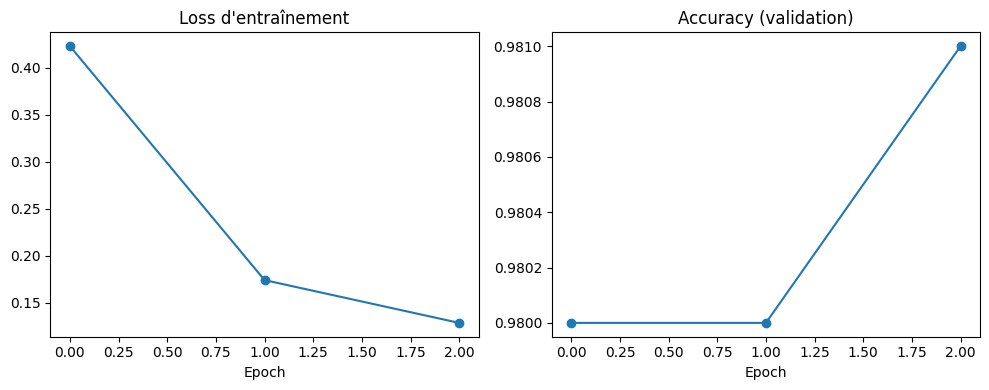

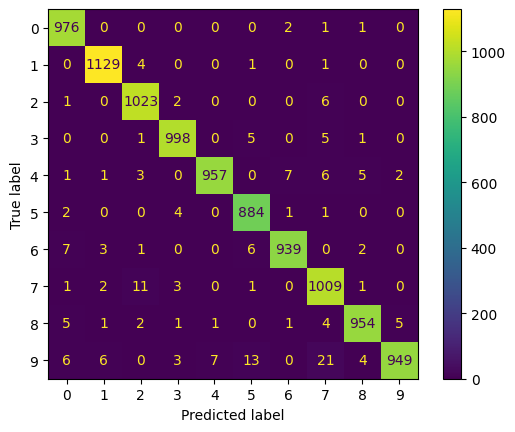

NameError: name 'json' is not defined

In [12]:
t_acc, t_f1, t_iou, preds, labels = evaluate_det(model, test_loader)
loss_loader = DataLoader(Subset(test_ds, list(range(2000))), batch_size=BATCH,
                         shuffle=False, num_workers=2, collate_fn=collate)
t_loss, t_cls_loss = detection_loss(model, loss_loader)
print(f"TEST | acc {t_acc:.4f} | F1 {t_f1:.4f} | IoU moyen {t_iou:.3f} "
      f"| loss totale {t_loss:.4f} | loss classif {t_cls_loss:.4f}")

results = {"Faster R-CNN": {"accuracy": t_acc, "f1": t_f1, "loss": t_loss,
                            "loss_classifier": t_cls_loss, "mean_iou": t_iou,
                            "time_s": train_time}}

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(history["train_loss"], marker="o")
plt.title("Loss d'entraînement"); plt.xlabel("Epoch")
plt.subplot(1, 2, 2); plt.plot(history["val_acc"], marker="o")
plt.title("Accuracy (validation)"); plt.xlabel("Epoch")
plt.tight_layout(); plt.savefig("frcnn_curves.png", dpi=150); plt.show()

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(labels, preds, labels=list(range(10)))
plt.savefig("frcnn_confusion.png", dpi=150); plt.show()

json.dump(results, open("results_frcnn.json", "w"), indent=2)

In [13]:
import json
json.dump(results, open("results_frcnn.json", "w"), indent=2)
print(results)

{'Faster R-CNN': {'accuracy': 0.9818, 'f1': 0.9816832509189979, 'loss': 0.12501985728740692, 'loss_classifier': 0.058319061368703844, 'mean_iou': 0.924342648178339, 'time_s': 395.42557549476624}}


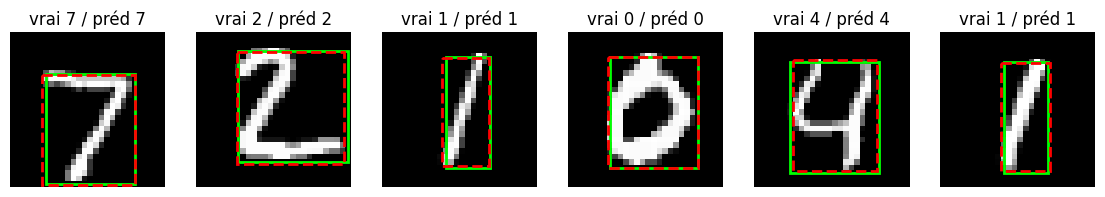

In [14]:
import matplotlib.patches as patches
model.eval()
imgs, tgts = next(iter(test_loader))
with torch.no_grad():
    outs = model([im.to(device) for im in imgs[:6]])
fig, axs = plt.subplots(1, 6, figsize=(14, 3))
for ax, im, t, o in zip(axs, imgs[:6], tgts[:6], outs):
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
    x1, y1, x2, y2 = t["boxes"][0].tolist()
    ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec="lime", lw=2))
    if len(o["scores"]):
        k = o["scores"].argmax()
        bx = o["boxes"][k].cpu().tolist()
        ax.add_patch(patches.Rectangle((bx[0], bx[1]), bx[2]-bx[0], bx[3]-bx[1],
                                       fill=False, ec="red", lw=2, ls="--"))
        ax.set_title(f"vrai {int(t['labels'][0])-1} / préd {int(o['labels'][k])-1}")
plt.savefig("frcnn_examples.png", dpi=150, bbox_inches="tight"); plt.show()